In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from matplotlib import rcParams
import plotting_functions

In [2]:
# Load data
base_path = "data_Figs/Fig_AUC_and_Fix_Prob_Toy_model/"
auc_sim = np.loadtxt(base_path + "AUC_vs_f0_sim.txt")
auc_null = np.loadtxt(base_path + "AUC_vs_f0_null.txt")
fix_top_50 = np.loadtxt(base_path + "fix_sim_score_top.txt")
fix_bottom_50 = np.loadtxt(base_path + "fix_sim_score_bottom.txt")
fix_top_25 = np.loadtxt(base_path + "fix_sim_score_top_25.txt")
fix_bottom_25 = np.loadtxt(base_path + "fix_sim_score_bottom_25.txt")
fix_all = np.loadtxt(base_path + "fix_prob_frequency_null.txt")

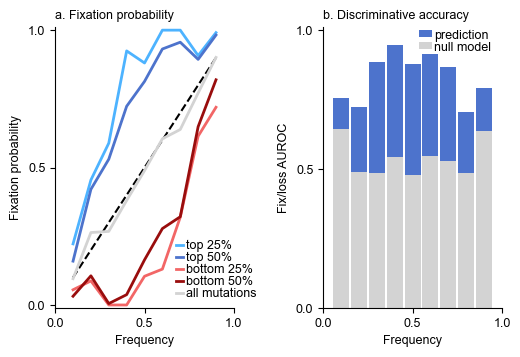

In [5]:
ms = 6
lw = 2
# Frequency values from 0.1 to 0.9
frequencies = np.arange(0.1, 1.0, 0.1)

# Style and params
bar_width = 0.09
# Create subplots
fig, axs = plt.subplots(1, 2, figsize=plotting_functions.get_figsize("vertical"))

# ----------------------
# Panel B: AUROC bar plot
# ----------------------
ax = axs[1]
ax.bar(frequencies , auc_sim, width=bar_width, color=(0.3, 0.45, 0.8), label="prediction")
ax.bar(frequencies , auc_null, width=bar_width, color='lightgray', label="null model")

ax.set_ylim(0.0, 1.01)
ax.set_xlim(0.0, 1.0)
ax.set_xticks([0.0,0.5, 1.0])
ax.set_yticks([0.0,0.5, 1.0])

ax.set_xlabel("Frequency")
ax.set_ylabel("Fix/loss AUROC")
ax.set_title("b. Discriminative accuracy", loc='left')
ax.legend(loc=(0.51, 0.89), frameon=False,handlelength=1.0, handleheight=0.5, handletextpad=0.2, labelspacing=0.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# ----------------------

# ----------------------
# Panel A: Fixation probability
# ----------------------
ax = axs[0]
ax.plot(frequencies, frequencies, '--', color='black', label="")

ax.plot(frequencies, fix_top_25, color=(0.3, 0.7, 1.0), label="top 25%", linewidth=lw)
ax.plot(frequencies, fix_top_50, color=(0.3, 0.45, 0.8), label="top 50%", linewidth=lw)
ax.plot(frequencies, fix_bottom_25, color=(0.95, 0.4, 0.4), label="bottom 25%", linewidth=lw)
ax.plot(frequencies, fix_bottom_50, color=(0.6, 0.05, 0.05), label="bottom 50%", linewidth=lw)
ax.plot(frequencies, fix_all, color='lightgray', label="all mutations", linewidth=lw)

ax.set_ylim(-0.01, 1.01)
ax.set_xlim(0.0, 1.0)
ax.set_xticks([0.0,0.5, 1.0])
ax.set_yticks([0.0,0.5, 1.0])

ax.set_xlabel("Frequency", )
ax.set_ylabel("Fixation probability",)
ax.set_title("a. Fixation probability", loc='left')
ax.legend(loc=(0.65, 0.01),handlelength=0.5, handleheight=0.5, handletextpad=0.3, labelspacing=0.0,  frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)
# ----------------------
# Layout adjustments
# ----------------------
#plt.subplots_adjust(left=0.06, right=0.96, top=0.95, bottom=0.12, wspace=0.5)
plt.subplots_adjust(left=0.1, right=0.95, top=0.95, bottom=0.15, wspace=0.5, hspace=0.4)

#fig.text(0.5, 0.01, 'Mutation frequency', ha='center', va='center')

# Save or show
plt.savefig("AUC_and_fix_artificial_q_4_L_20_py.pdf")
plt.show()